# Exp2 leave-one-galaxy-out analysis

This notebook keeps four evaluation domains separate: **In-Distribution Test**, **Held-Out Test**, **Raw In-Domain**, and **Raw Held-Out**. Metrics are always calculated for all four domains. Plotting the two in-domain reference domains can be disabled to focus on genuine cross-galaxy generalization.

`Held-Out Test` (`out.pt`) is the authoritative generalization result. `Raw Held-Out` independently reconstructs the same full trajectory from processed HDF5 files and is used as a preprocessing-consistency check. Their predictions are required to agree before figures and statistics are saved. RMSE, MAE, R2, and OutlierFrac are calculated in the configured transformed-target space (currently `log10(1 + SFR)`); OutlierFrac is a 0–1 fraction using an absolute transformed-target error greater than 1.

In [4]:
# Plot controls: held-out figures are always generated.
PLOT_IN_DISTRIBUTION = False  # cached test.pt from galaxies participating in training
PLOT_IN_DOMAIN = False        # complete raw trajectories of training galaxies

# Leave empty to analyze the latest completed result for every Exp2 fold.
# Example: RESULT_DIRS = [r'D:\\research\\ai+MACERsimulation\\MACNet-v1\\Results\\Exp2_LOOfiducial4_20260810_134618']
RESULT_DIRS = []


Analyzing Exp2_SFRConvNet_LOO_disk_galaxy_fiducial20260810_134247

Analyzing: Exp2_SFRConvNet_LOO_disk_galaxy_fiducial20260810_134247
Cache prefix: Exp2_InstantSFR_NoInitialStellarDensity_LOO_disk_galaxy_fiducial_
[PASS] Analysis split contract: in-domain=['disk_galaxy_fiducial_4', 'disk_galaxy_fiducial_7'], held-out=['disk_galaxy_fiducial']
  Predicting Raw In-Domain: disk_galaxy_fiducial_4 (8816 snapshots)
  Predicting Raw In-Domain: disk_galaxy_fiducial_7 (7071 snapshots)
  Predicting Raw Held-Out: disk_galaxy_fiducial (8475 snapshots)
[PASS] Cached held-out and raw held-out trajectories agree: max |time diff|=4.578e-07 Gyr, max |prediction diff|=0.000e+00


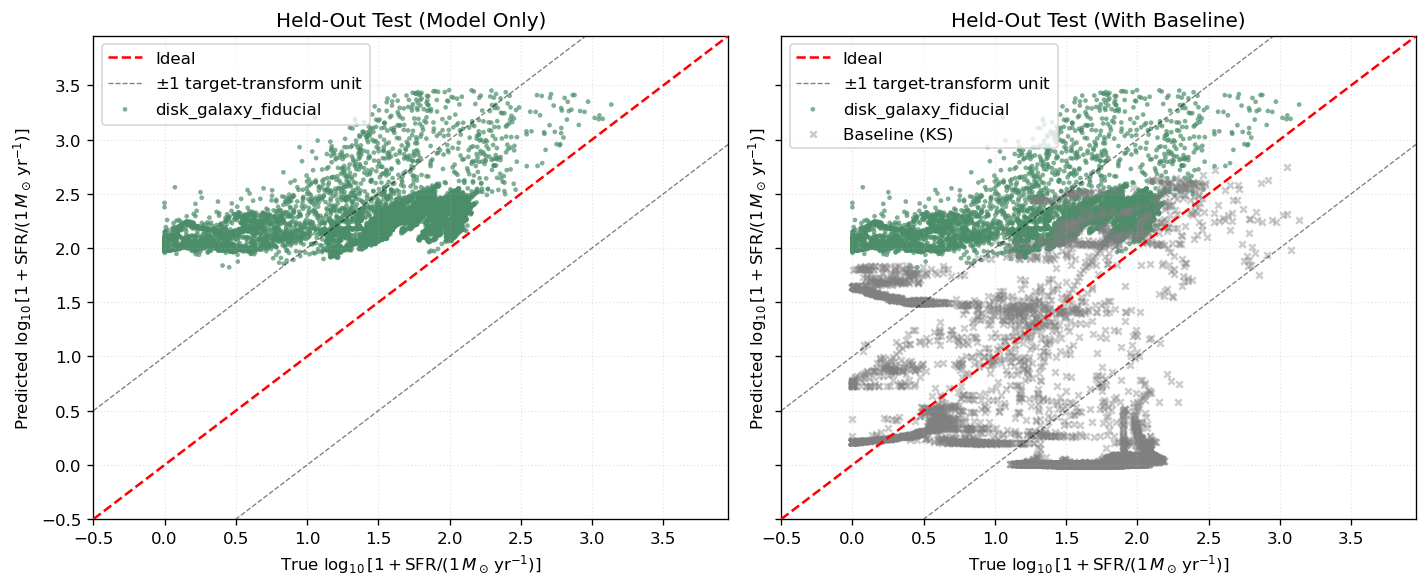

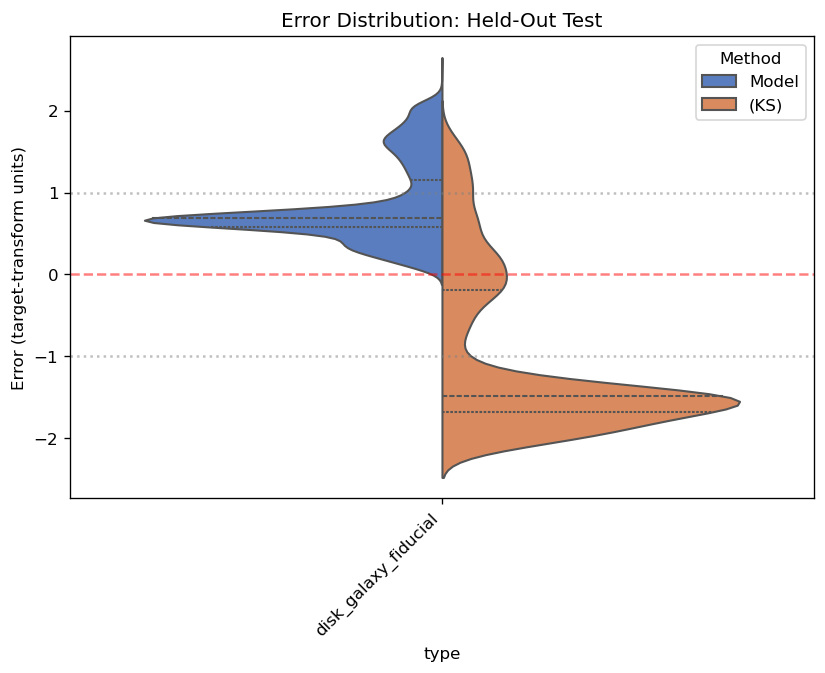

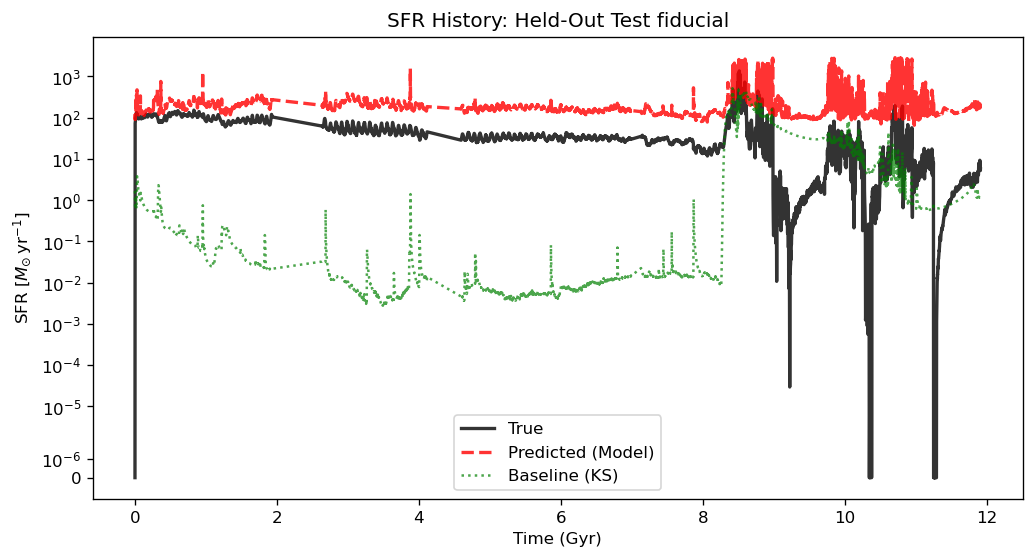

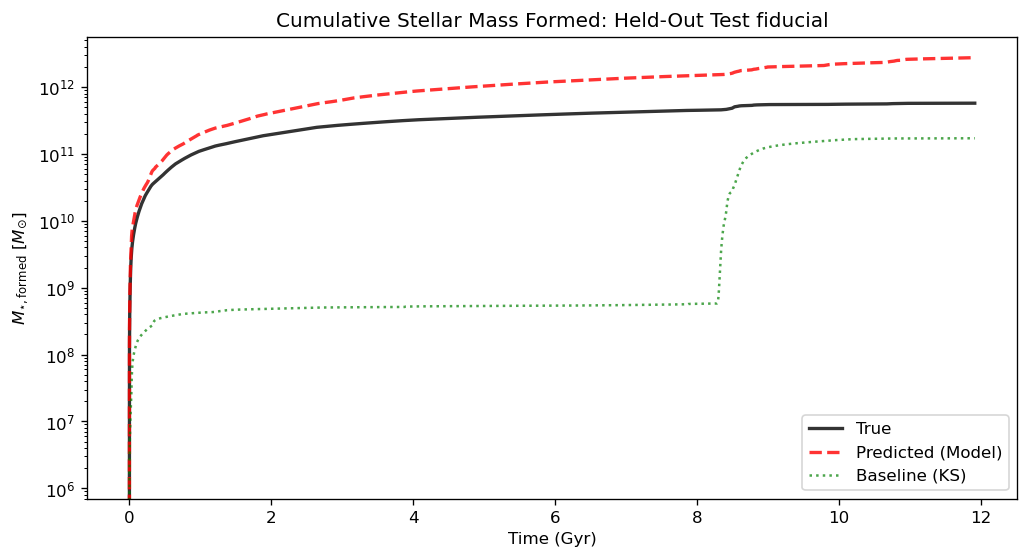

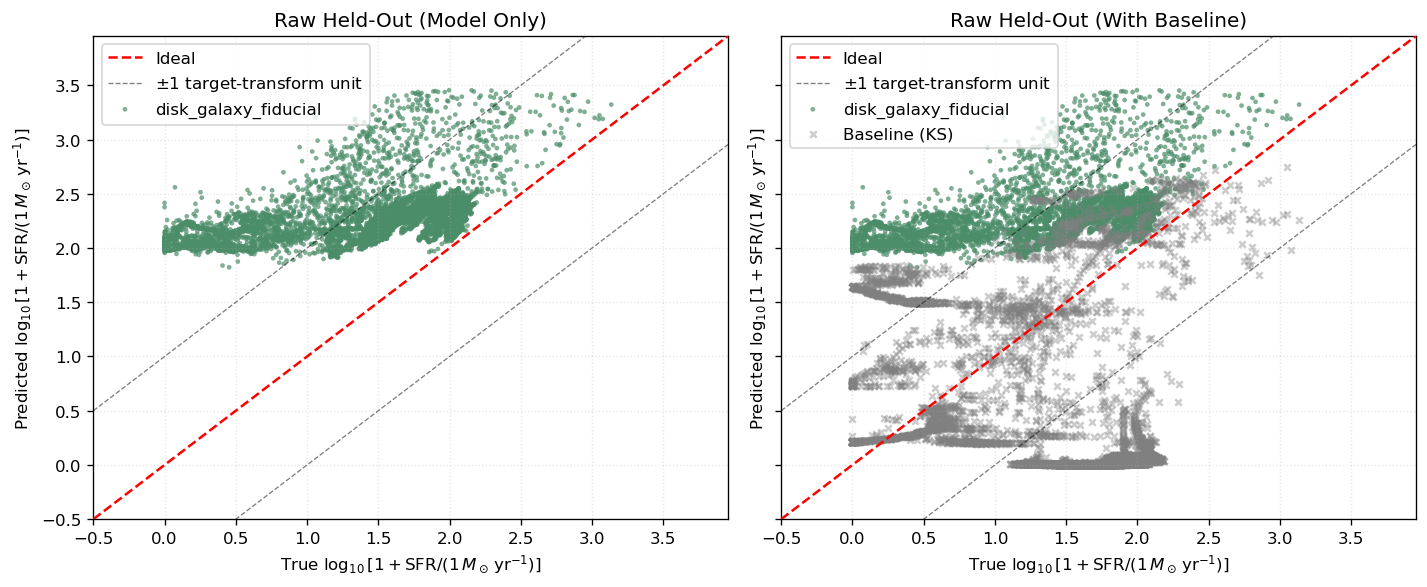

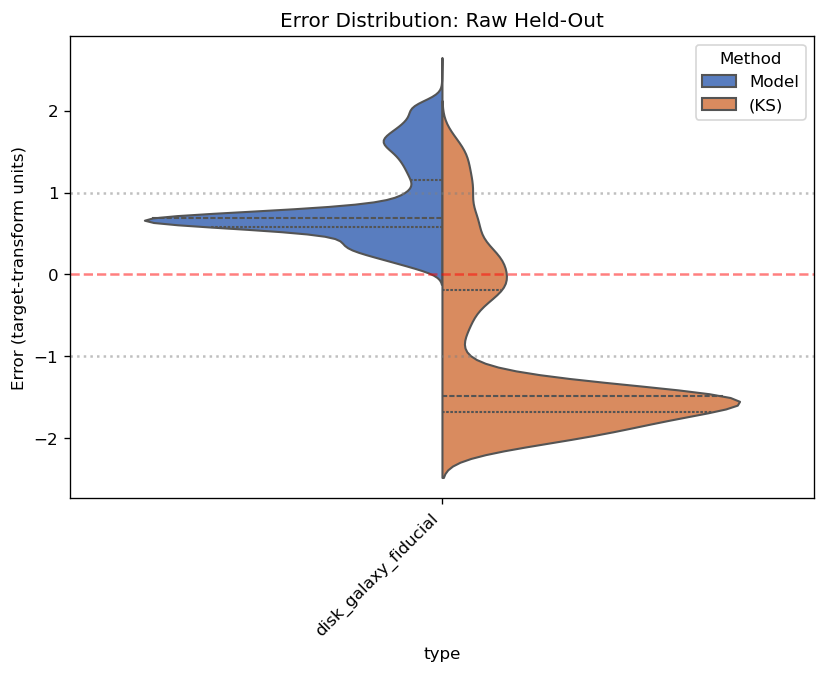

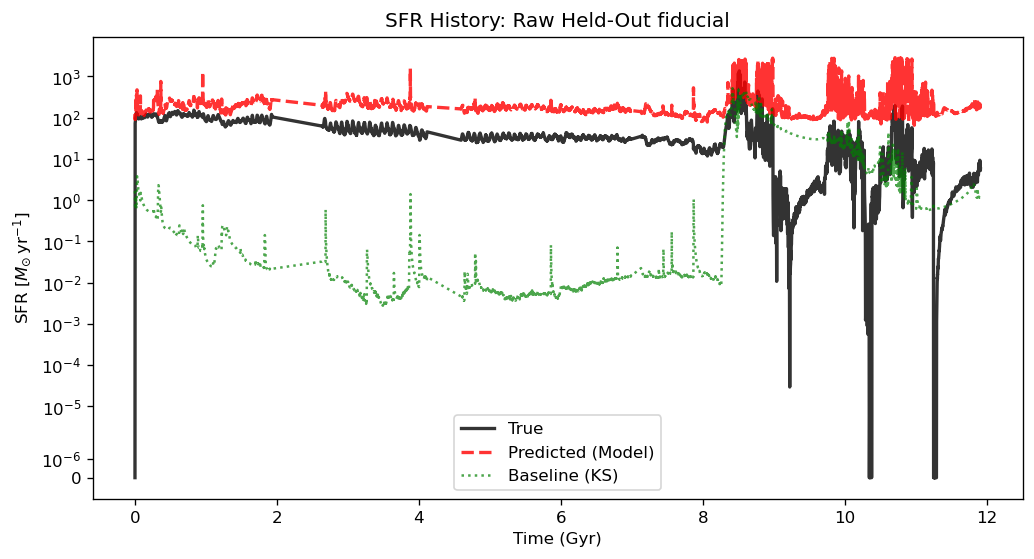

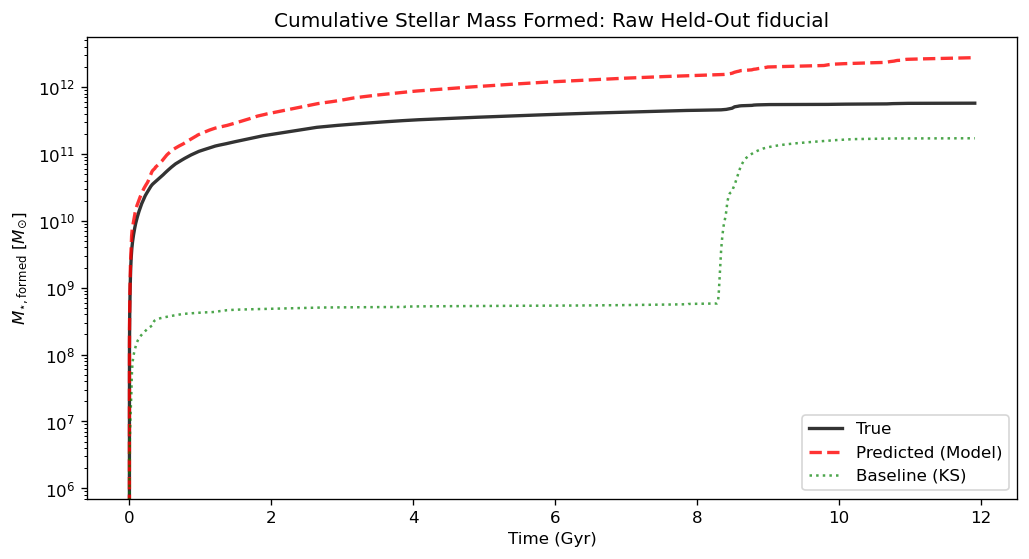

Saved domain-separated Exp2 analysis to: D:\research\ai+MACERsimulation\MACNet-v1\Results\Exp2_SFRConvNet_LOO_disk_galaxy_fiducial20260810_134247

Analyzing Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_420260810_134618

Analyzing: Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_420260810_134618
Cache prefix: Exp2_InstantSFR_NoInitialStellarDensity_LOO_disk_galaxy_fiducial_4_
[PASS] Analysis split contract: in-domain=['disk_galaxy_fiducial', 'disk_galaxy_fiducial_7'], held-out=['disk_galaxy_fiducial_4']
  Predicting Raw In-Domain: disk_galaxy_fiducial (8475 snapshots)
  Predicting Raw In-Domain: disk_galaxy_fiducial_7 (7071 snapshots)
  Predicting Raw Held-Out: disk_galaxy_fiducial_4 (8816 snapshots)
[PASS] Cached held-out and raw held-out trajectories agree: max |time diff|=4.578e-07 Gyr, max |prediction diff|=0.000e+00


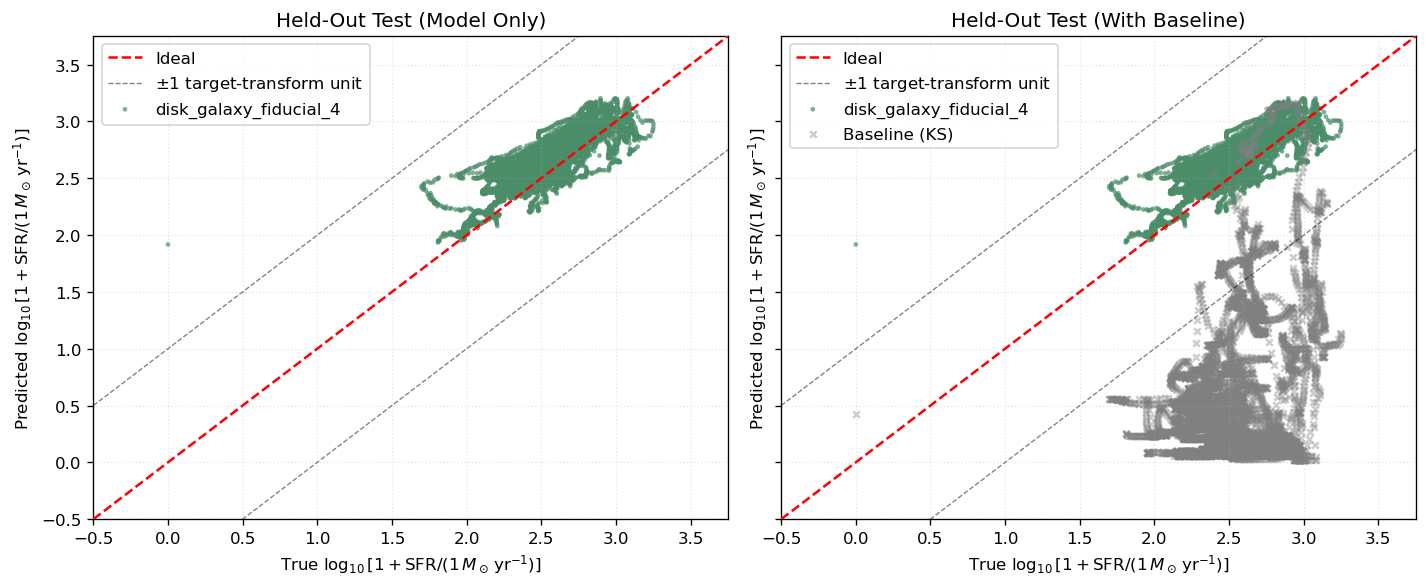

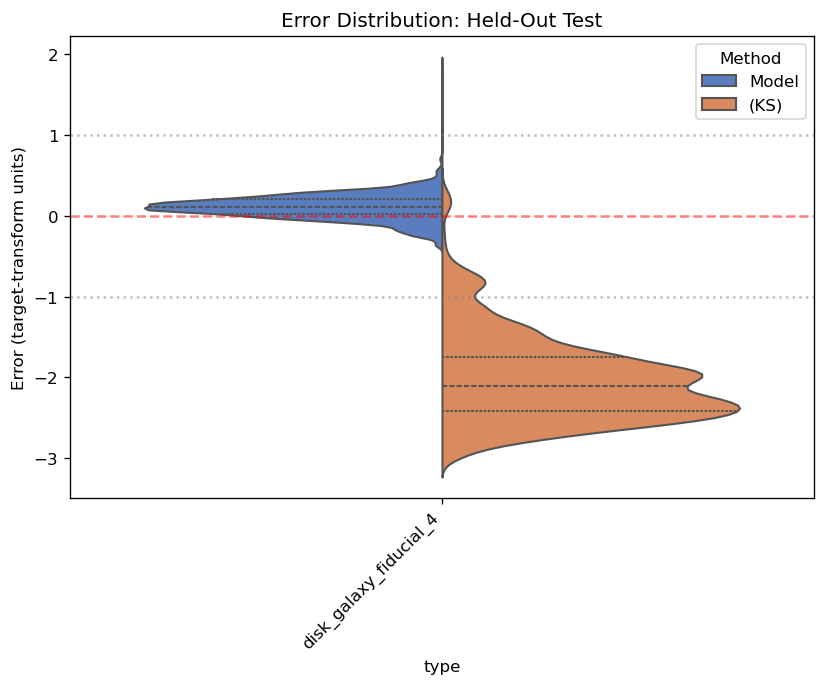

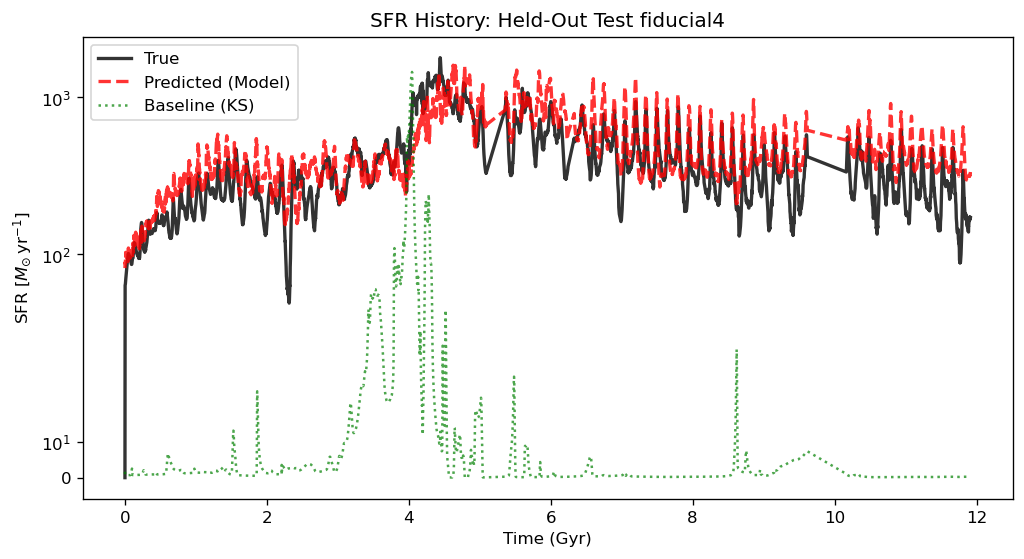

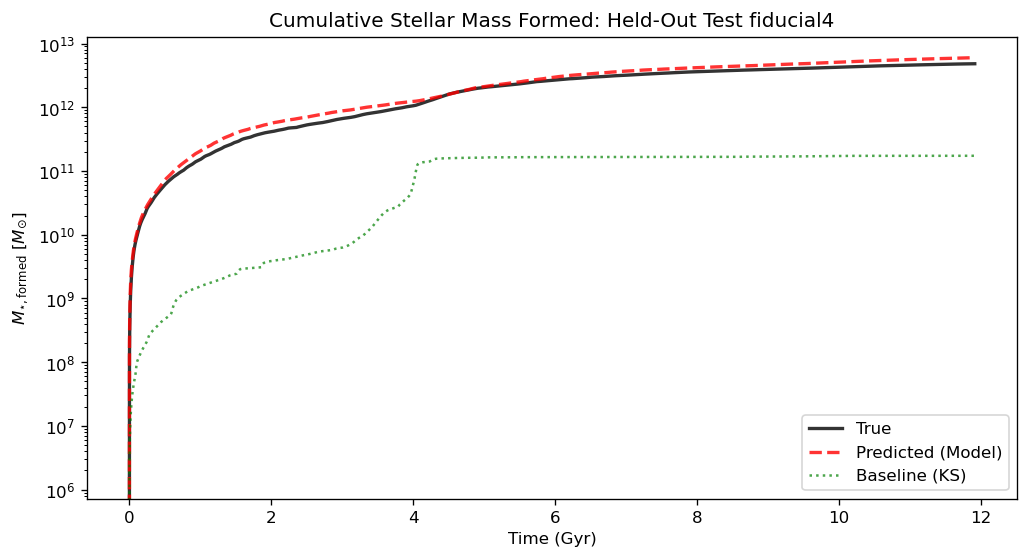

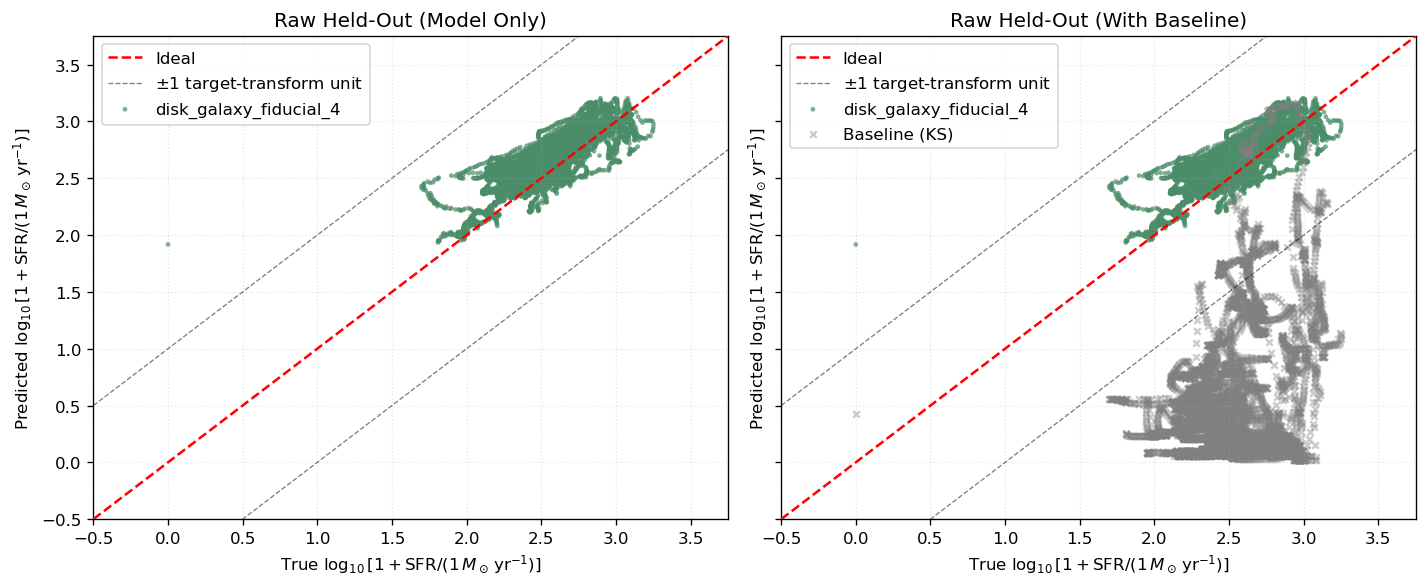

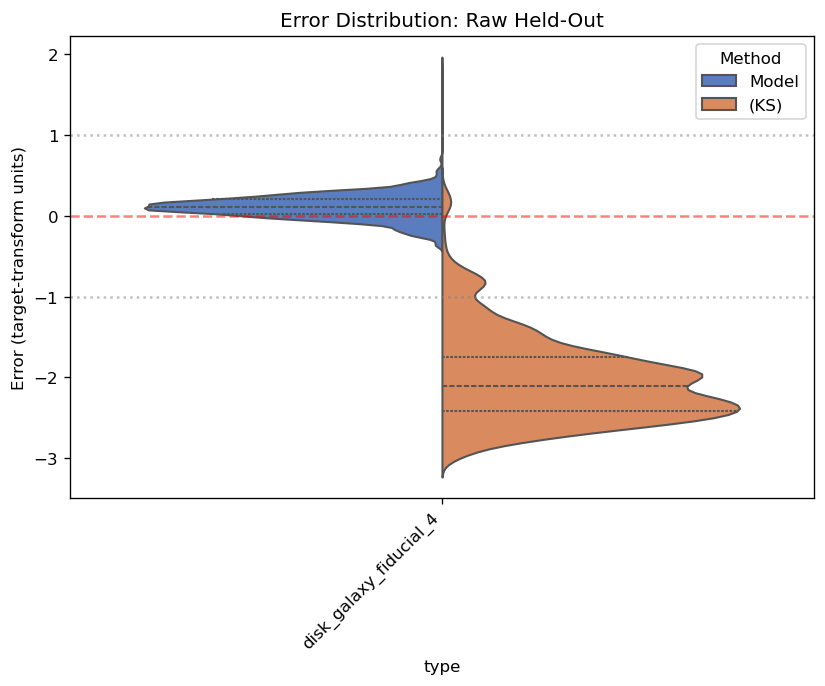

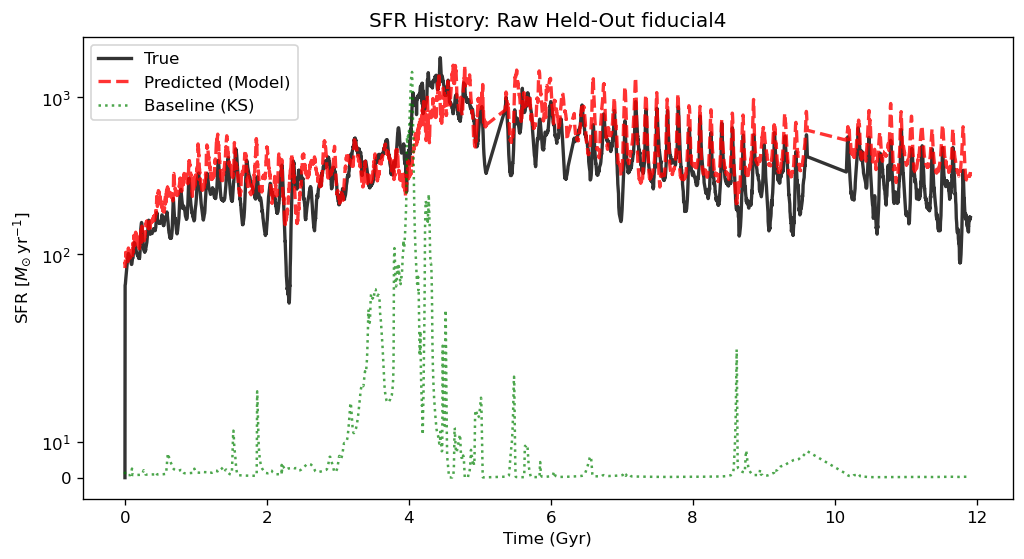

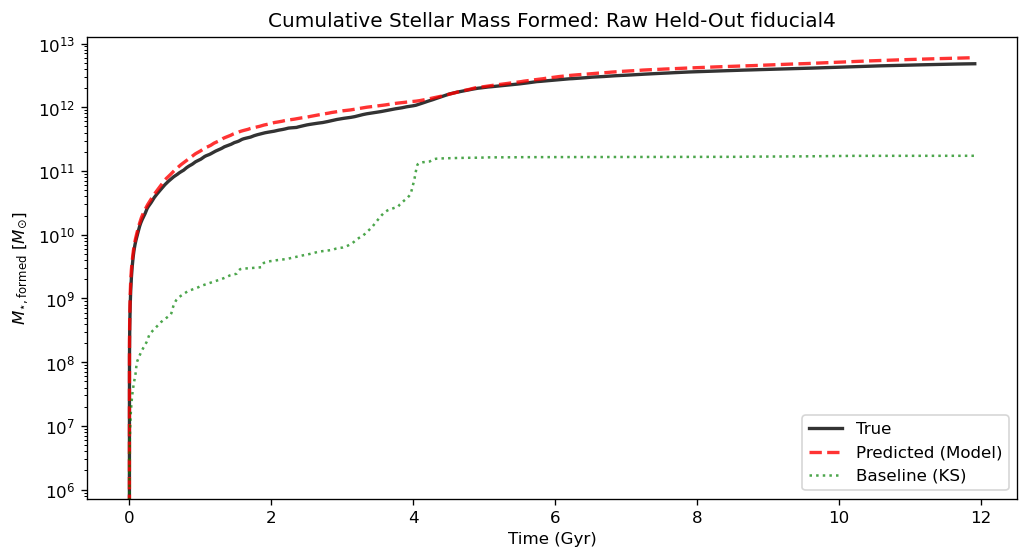

Saved domain-separated Exp2 analysis to: D:\research\ai+MACERsimulation\MACNet-v1\Results\Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_420260810_134618

Analyzing Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_720260810_134838

Analyzing: Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_720260810_134838
Cache prefix: Exp2_InstantSFR_NoInitialStellarDensity_LOO_disk_galaxy_fiducial_7_
[PASS] Analysis split contract: in-domain=['disk_galaxy_fiducial', 'disk_galaxy_fiducial_4'], held-out=['disk_galaxy_fiducial_7']
  Predicting Raw In-Domain: disk_galaxy_fiducial (8475 snapshots)
  Predicting Raw In-Domain: disk_galaxy_fiducial_4 (8816 snapshots)
  Predicting Raw Held-Out: disk_galaxy_fiducial_7 (7071 snapshots)
[PASS] Cached held-out and raw held-out trajectories agree: max |time diff|=4.578e-07 Gyr, max |prediction diff|=0.000e+00


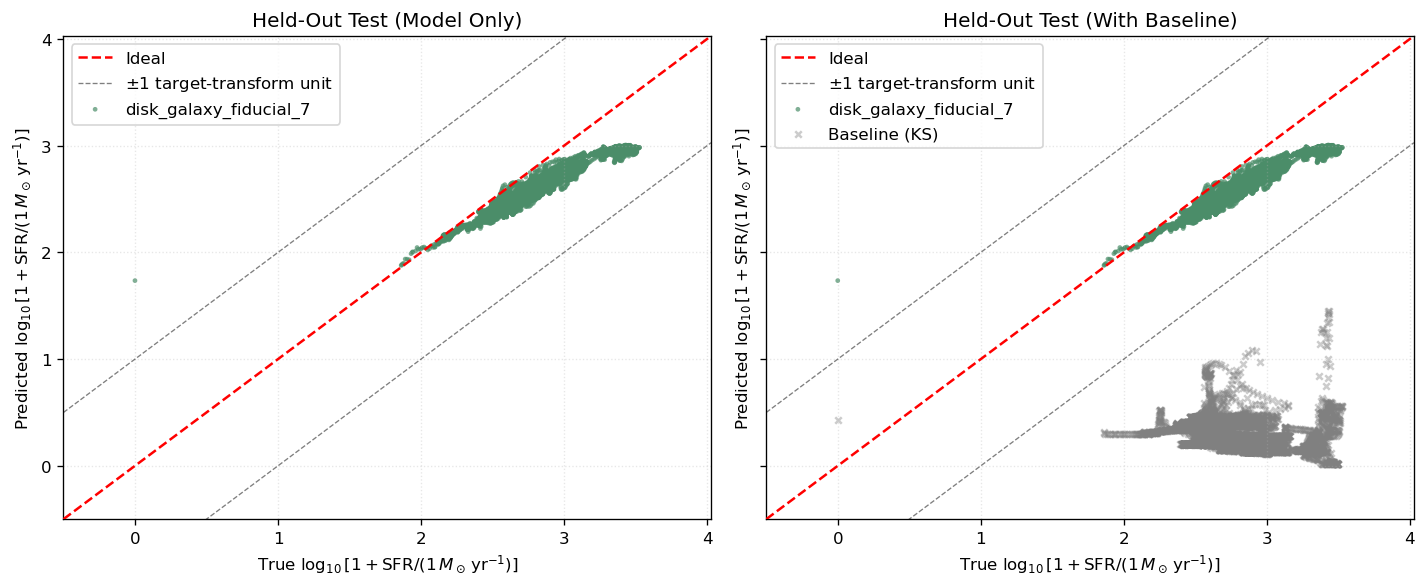

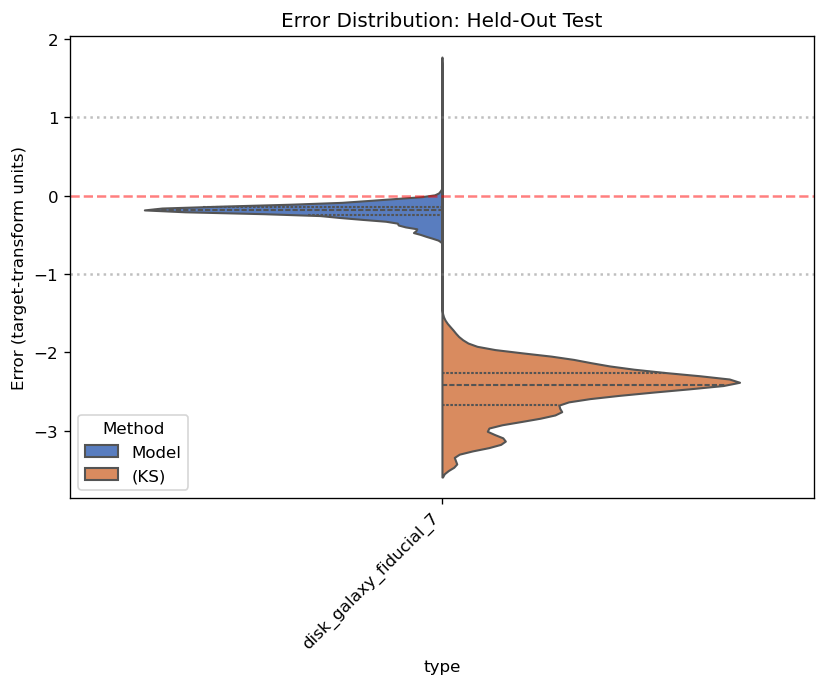

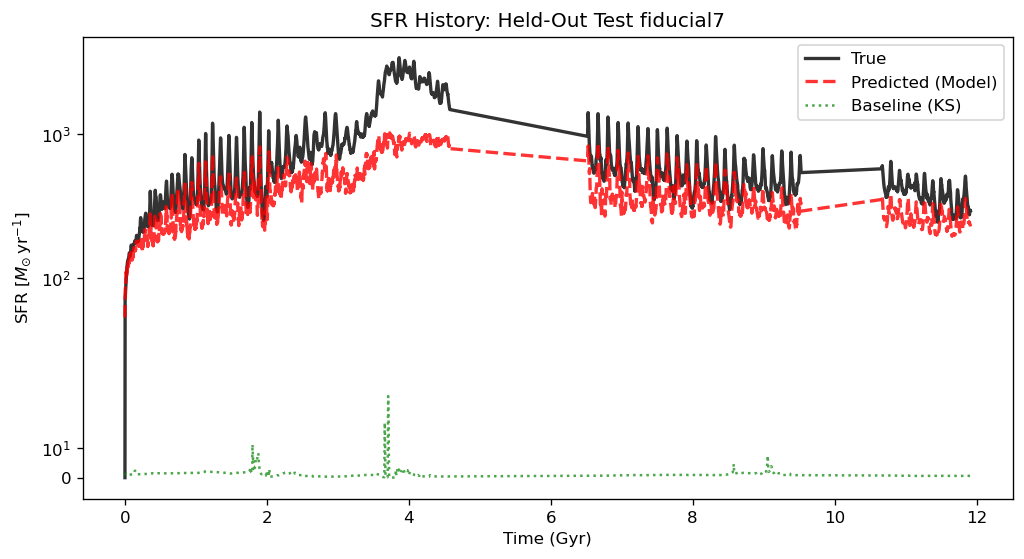

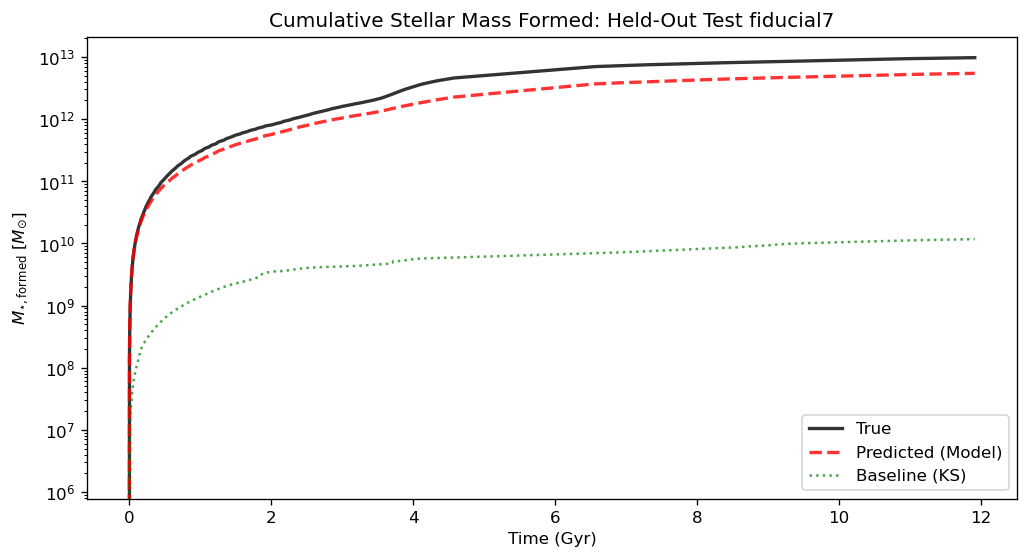

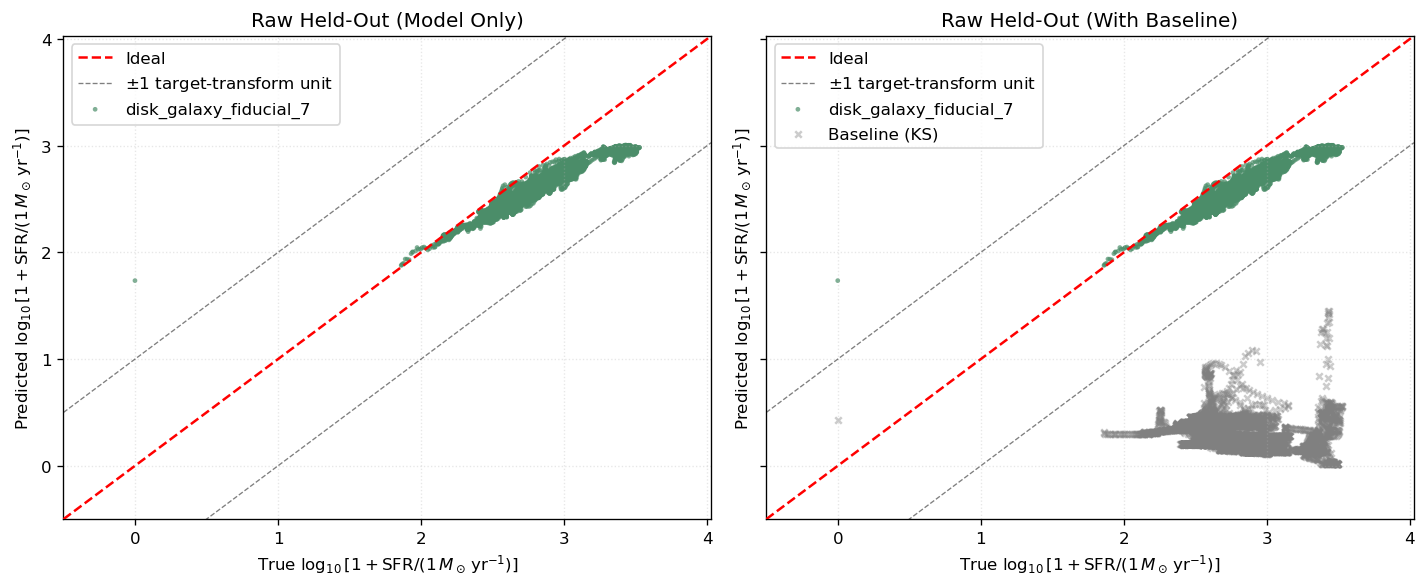

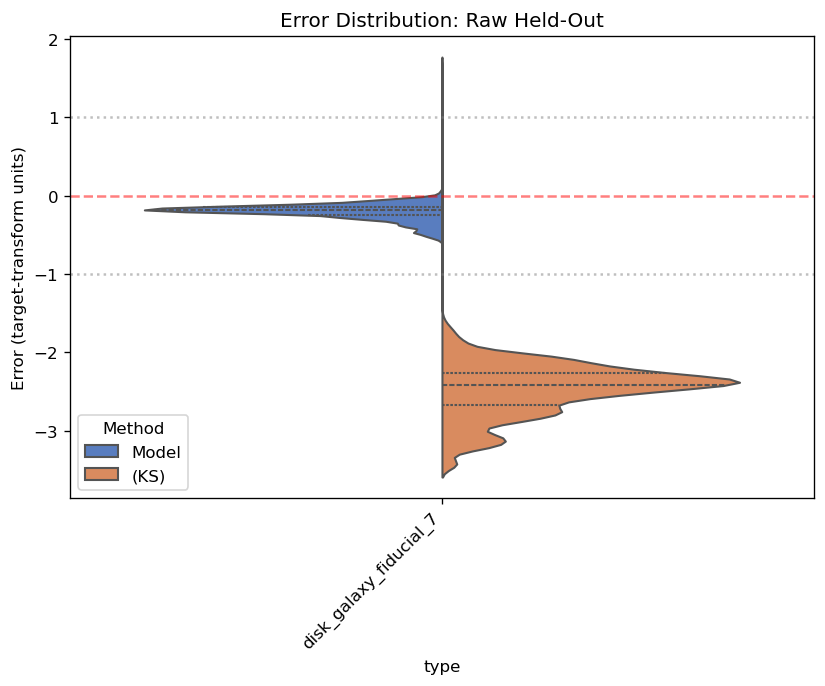

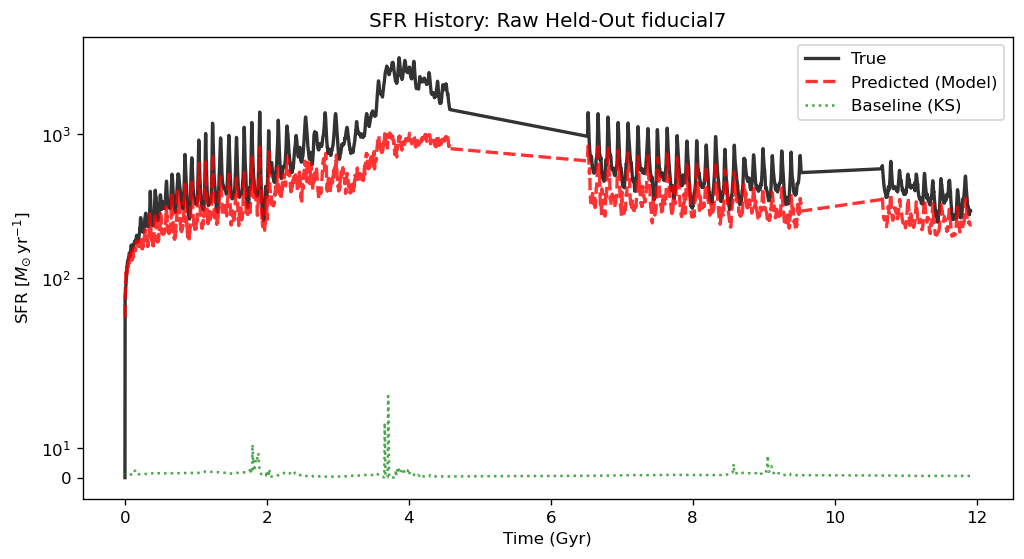

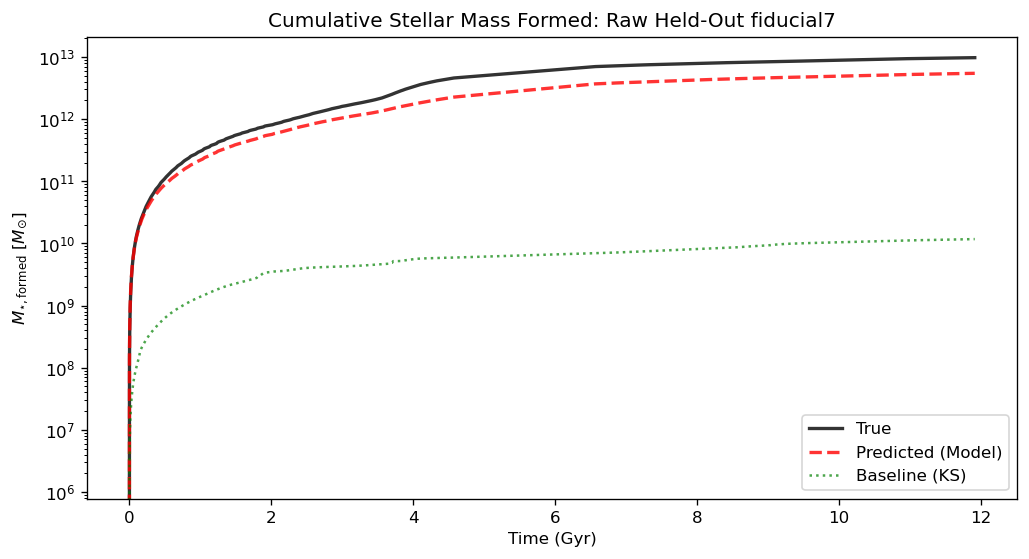

Saved domain-separated Exp2 analysis to: D:\research\ai+MACERsimulation\MACNet-v1\Results\Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_720260810_134838


,ResultDir,HeldOut,Dataset,RMSE,MAE,R2,OutlierFrac (|target error|>1)
0,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial202608...,fiducial,In-Distribution Test,0.058167,0.022089,0.963549,0.000629
1,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial202608...,fiducial,Held-Out Test,0.995881,0.859239,-2.060318,0.277168
2,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial202608...,fiducial,Raw In-Domain,0.034306,0.020171,0.986728,0.000126
3,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial202608...,fiducial,Raw Held-Out,0.995881,0.859239,-2.060318,0.277168
4,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_42026...,fiducial4,In-Distribution Test,0.093979,0.060136,0.986622,0.000322
5,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_42026...,fiducial4,Held-Out Test,0.188134,0.152310,0.468610,0.000113
6,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_42026...,fiducial4,Raw In-Domain,0.085999,0.057413,0.989051,0.000193
7,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_42026...,fiducial4,Raw Held-Out,0.188134,0.152310,0.468610,0.000113
8,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_72026...,fiducial7,In-Distribution Test,0.051185,0.027308,0.994629,0.000289
9,Exp2_SFRConvNet_LOO_disk_galaxy_fiducial_72026...,fiducial7,Held-Out Test,0.229866,0.204542,0.353009,0.000141


In [6]:
import importlib
import json
import sys
from pathlib import Path

import pandas as pd
import torch
from IPython.display import display

cwd = Path.cwd().resolve()
project_root = next((p for p in (cwd, *cwd.parents) if (p / 'Experiment').is_dir() and (p / '.config').is_dir()), None)
if project_root is None:
    raise RuntimeError('Could not locate the MACNet-v1 project root.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from VisualScripts.ResultAnalysis import analysis_utils, analyze_exp2

# Jupyter caches imported modules. Reload both layers so this notebook always
# uses the current on-disk function signatures and metric definitions.
importlib.reload(analysis_utils)
importlib.reload(analyze_exp2)
analyze_result = analyze_exp2.analyze_result
_discover_latest_fold_results = analyze_exp2._discover_latest_fold_results

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
result_dirs = [Path(path) for path in RESULT_DIRS] if RESULT_DIRS else _discover_latest_fold_results(project_root / 'Results')
if not result_dirs:
    raise RuntimeError('No completed leave-one-galaxy-out Exp2 results were found.')

metric_frames = []
for result_dir in result_dirs:
    print(f'\nAnalyzing {result_dir.name}')
    metrics_path = analyze_result(
        result_dir,
        device,
        plot_in_distribution=PLOT_IN_DISTRIBUTION,
        plot_in_domain=PLOT_IN_DOMAIN,
    )
    frame = pd.read_csv(metrics_path)
    analysis_metadata = json.loads((result_dir / 'exp2_analysis_metadata.json').read_text(encoding='utf-8'))
    frame.insert(0, 'HeldOut', analysis_metadata['held_out_groups'][0].removeprefix('disk_galaxy_').replace('_', ''))
    frame.insert(0, 'ResultDir', result_dir.name)
    metric_frames.append(frame)

metrics_all_folds = pd.concat(metric_frames, ignore_index=True)
metrics_all_folds.to_csv(project_root / 'Results' / 'Exp2_LOO_metrics_all_folds.csv', index=False)
display(metrics_all_folds)

In [7]:
# Cross-fold generalization summary. Held-Out Test is authoritative;
# Raw Held-Out should be numerically equivalent and acts as an independent pipeline check.
held_out_metrics = metrics_all_folds[
    metrics_all_folds['Dataset'].isin(['Held-Out Test', 'Raw Held-Out'])
].copy()
numeric_columns = ['RMSE', 'MAE', 'R2', 'OutlierFrac (|target error|>1)']
cross_fold_summary = held_out_metrics.groupby('Dataset')[numeric_columns].agg(['mean', 'std', 'min', 'max'])
cross_fold_summary.to_csv(project_root / 'Results' / 'Exp2_LOO_cross_fold_summary.csv')
display(cross_fold_summary)

RMSE                                     MAE            \
                   mean       std       min       max      mean       std   
Dataset                                                                     
Held-Out Test  0.471294  0.454785  0.188134  0.995881  0.405363  0.393934   
Raw Held-Out   0.471294  0.454785  0.188134  0.995881  0.405363  0.393934   

                                      R2                               \
                   min       max    mean       std       min      max   
Dataset                                                                 
Held-Out Test  0.15231  0.859239 -0.4129  1.427877 -2.060318  0.46861   
Raw Held-Out   0.15231  0.859239 -0.4129  1.427877 -2.060318  0.46861   

              OutlierFrac (|target error|>1)                               
                                        mean      std       min       max  
Dataset                                                                    
Held-Out Test                       0.092474  0.15995  0.000113  0.277168  
Raw Held-Out                        0.092474  0.15995  0.000113  0.277168